<a href="https://colab.research.google.com/github/BertieRoadnight313/Adv_ML/blob/main/Week_7_Tutorial.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import tensorflow as tf
print("TensorFlow version:", tf.__version__)
print("Num GPUs Available: ", len(tf.config.list_physical_devices('GPU')))

TensorFlow version: 2.21.0
Num GPUs Available:  1


In [3]:
import sys
import numpy as np
import keras
print("Python:", sys.version)
print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

keras.utils.set_random_seed(42)

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
TensorFlow: 2.21.0
Keras: 3.13.2
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [4]:
from keras.datasets import imdb
VOCAB_SIZE = 10_000
(train_data, train_labels), (test_data, test_labels) = imdb.load_data(
    num_words=VOCAB_SIZE
)
print("Train:", len(train_data))
print("Test:", len(test_data))
print("First label:", train_labels[0])
print("First review length:", len(train_data[0]))
print("Largest token id:", max(max(s) for s in train_data))



17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Train: 25000
Test: 25000
First label: 1
First review length: 218
Largest token id: 9999


In [5]:
word_index = imdb.get_word_index()
reverse_word_index = {v:k for k, v in word_index.items()}

decoded = " ".join(reverse_word_index.get(i-3, "?") for i in train_data[0])
print(decoded[:1000])

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
? this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert ? is an amazing actor and now the same being director ? father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the film as soon as it was released for ? and would recommend it to everyone to watch and the fly fishing was amazing really cried at the end it was so sad and you know what they say if you cry at a film it must have been good and this definitely was also ? to the two little boy's that played the ? of norman and paul they were just brilliant children are often left out of the ? list i think because the stars that play them all grown up are such a big profile for the whole film but these children are amazing and should

In [6]:
def vectorize_sequences(sequences, dimension=VOCAB_SIZE):
    results = np.zeros((len(sequences), dimension), dtype="float32")
    for i, sequence in enumerate(sequences):
        results[i, sequence] = 1.0
    return results

x_train = vectorize_sequences(train_data)
x_test = vectorize_sequences(test_data)
y_train = np.asarray(train_labels).astype("float32")
y_test = np.asarray(test_labels).astype("float32")

print(x_train.shape, y_train.shape)
print(x_test.shape, y_test.shape)


(25000, 10000) (25000,)
(25000, 10000) (25000,)


In [7]:
from keras import layers

model = keras.Sequential([
    keras.Input(shape=(VOCAB_SIZE,)),
    layers.Dense(16, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="rmsprop",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │       160,016 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 160,305 (626.19 KB)

 Trainable params: 160,305 (626.19 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
history = model.fit(
    x_train, y_train,
    epochs=8,
    batch_size=512,
    validation_split=0.2,
    verbose=1
)

test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print("Test loss:", test_loss)
print("Test accuracy:", test_acc)


Epoch 1/8
40/40 ━━━━━━━━━━━━━━━━━━━━ 6s 80ms/step - accuracy: 0.7965 - loss: 0.4915 - val_accuracy: 0.8434 - val_loss: 0.3863
Epoch 2/8
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.8998 - loss: 0.2899 - val_accuracy: 0.8890 - val_loss: 0.2908
Epoch 3/8
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.9212 - loss: 0.2251 - val_accuracy: 0.8912 - val_loss: 0.2751
Epoch 4/8
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.9341 - loss: 0.1867 - val_accuracy: 0.8906 - val_loss: 0.2788
Epoch 5/8
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.9449 - loss: 0.1590 - val_accuracy: 0.8920 - val_loss: 0.2844
Epoch 6/8
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.9503 - loss: 0.1406 - val_accuracy: 0.8902 - val_loss: 0.2985
Epoch 7/8
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.9586 - loss: 0.1230 - val_accuracy: 0.8870 - val_loss: 0.3104
Epoch 8/8
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.9638 - loss: 0.1095 - val_accuracy: 0.8872 - val_loss:

In [10]:
experiment_model = keras.Sequential([
    keras.Input(shape=(VOCAB_SIZE,)),
    layers.Dense(16, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

experiment_model.compile(
    optimizer="rmsprop",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

experiment_history = experiment_model.fit(
    x_train, y_train,
    epochs=8, batch_size=512,
    validation_split=0.2, verbose=0
)


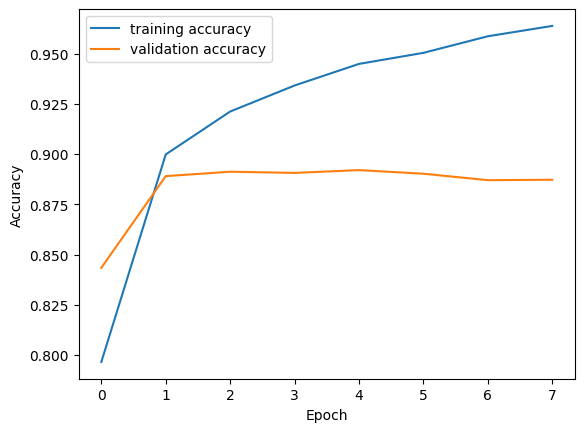

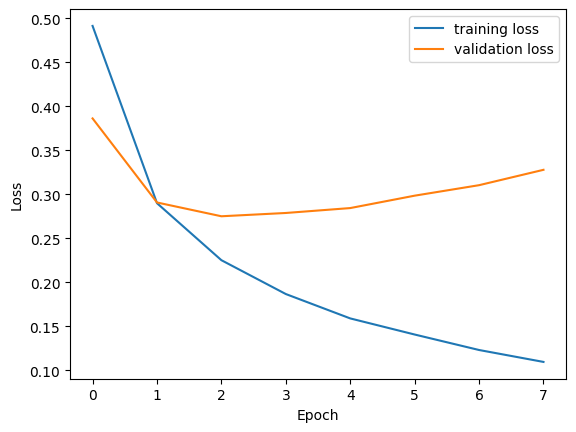

In [11]:
import matplotlib.pyplot as plt

h = history.history

plt.figure()
plt.plot(h["accuracy"], label="training accuracy")
plt.plot(h["val_accuracy"], label="validation accuracy")
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.legend(); plt.show()

plt.figure()
plt.plot(h["loss"], label="training loss")
plt.plot(h["val_loss"], label="validation loss")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend(); plt.show()


In [12]:
from keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

model_es = keras.Sequential([
    keras.Input(shape=(VOCAB_SIZE,)),
    layers.Dense(16, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

model_es.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

history_es = model_es.fit(
    x_train, y_train,
    epochs=20, batch_size=512,
    validation_split=0.2,
    callbacks=[early_stop], verbose=1
)

print("Epochs actually run:", len(history_es.history["loss"]))
sample_ids = [0, 10, 25, 100, 250]
probabilities = model_es.predict(x_test[sample_ids], verbose=0).ravel()

for idx, p, actual in zip(sample_ids, probabilities, y_test[sample_ids]):
    pred = int(p >= 0.5)
    print(f"Review {idx}: probability={p:.3f}, predicted={pred}, actual={int(actual)}")


Epoch 1/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 4s 61ms/step - accuracy: 0.8026 - loss: 0.5113 - val_accuracy: 0.8766 - val_loss: 0.3501
Epoch 2/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.9064 - loss: 0.2647 - val_accuracy: 0.8912 - val_loss: 0.2816
Epoch 3/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.9370 - loss: 0.1882 - val_accuracy: 0.8946 - val_loss: 0.2736
Epoch 4/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.9539 - loss: 0.1452 - val_accuracy: 0.8912 - val_loss: 0.2879
Epoch 5/20
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.9638 - loss: 0.1156 - val_accuracy: 0.8844 - val_loss: 0.3202
Epochs actually run: 5
Review 0: probability=0.243, predicted=0, actual=0
Review 10: probability=0.957, predicted=1, actual=1
Review 25: probability=0.979, predicted=1, actual=1
Review 100: probability=0.068, predicted=0, actual=1
Review 250: probability=0.186, predicted=0, actual=1


In [13]:
from keras.datasets import california_housing

(x_train_r, y_train_r), (x_test_r, y_test_r) = california_housing.load_data(
    version="small"
)

print(x_train_r.shape, y_train_r.shape)
print(x_test_r.shape, y_test_r.shape)
reg_model = keras.Sequential([
    keras.Input(shape=(x_train_r.shape[1],)),
    layers.Dense(32, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(1)
])

reg_model.compile(optimizer="adam", loss="mse", metrics=["mae"])

reg_history = reg_model.fit(
    x_train_r, y_train_r,
    epochs=30, batch_size=32,
    validation_split=0.2,
    callbacks=[EarlyStopping(monitor="val_loss", patience=3,
                              restore_best_weights=True)],
    verbose=0
)

test_mse, test_mae = reg_model.evaluate(x_test_r, y_test_r, verbose=0)
print("Test MAE:", test_mae)


743530/743530 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
(480, 8) (480,)
(120, 8) (120,)
Test MAE: 93132.6484375
